# Knowledge Distillation — Attention Transfer (AT) Experiment

**Setup:** CIFAR-10 · ResNet-34 teacher · ResNet-18 student

This notebook mirrors the Vanilla KD notebook's structure, but only the **AT student is trained here**.
The teacher (ResNet-34) and baseline (ResNet-18, no distillation) are **loaded from the weights already saved
in Drive** and kept frozen / eval-only.

- CIFAR-10 is stored persistently in Google Drive.
- Training defaults to **35 epochs**, matching the AT student config used previously.
- Start with the smoke-test cell (5 epochs) before committing to the full run.
- Best AT student weights are saved as `attention_transfer_resnet18.pth`.
- A resume checkpoint is saved every epoch so a Colab disconnect does not waste completed epochs.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import sys
import time
import json
import random
import numpy as np
import torch

PROJECT_DIR = Path("/content/drive/MyDrive/kd_experiments")
DATA_DIR = PROJECT_DIR / "data"
WEIGHTS_DIR = PROJECT_DIR / "weights"
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
LOGS_DIR = PROJECT_DIR / "logs"

for directory in [
    PROJECT_DIR, DATA_DIR, WEIGHTS_DIR, CHECKPOINTS_DIR, RESULTS_DIR, LOGS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project:", PROJECT_DIR)
print("Data:   ", DATA_DIR)
print("Weights:", WEIGHTS_DIR)
print("Device: ", device)

if torch.cuda.is_available():
    print("GPU:    ", torch.cuda.get_device_name(0))
    print("CUDA:   ", torch.version.cuda)

Mounted at /content/drive
Project: /content/drive/MyDrive/kd_experiments
Data:    /content/drive/MyDrive/kd_experiments/data
Weights: /content/drive/MyDrive/kd_experiments/weights
Device:  cuda
GPU:     Tesla T4
CUDA:    12.8


In [2]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms

from tqdm.auto import tqdm
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

print("Seed:", SEED)
print("cuDNN benchmark:", torch.backends.cudnn.benchmark)

Seed: 42
cuDNN benchmark: True


In [4]:
CIFAR10_ROOT = str(DATA_DIR)

# CIFAR-10 normalization (same as vanilla KD)
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = torchvision.datasets.CIFAR10(
    root=CIFAR10_ROOT,
    train=True,
    download=True,
    transform=train_transform,
)

test_dataset = torchvision.datasets.CIFAR10(
    root=CIFAR10_ROOT,
    train=False,
    download=True,
    transform=test_transform,
)

print("Train samples:", len(train_dataset))
print("Test samples: ", len(test_dataset))
print("Dataset root: ", CIFAR10_ROOT)

Train samples: 50000
Test samples:  10000
Dataset root:  /content/drive/MyDrive/kd_experiments/data


In [5]:
BATCH_SIZE = 128
NUM_WORKERS = 2

pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)

print("Batch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Batch size: 128
Train batches: 391
Test batches: 79


## Models

Same CIFAR-style ResNet-18 / ResNet-34 definitions as vanilla KD , so the saved
teacher/baseline `.pth` files load in without any shape mismatches.

In [6]:
def cifar_resnet18(num_classes=10):
    model = ResNet(
        block=BasicBlock,
        layers=[2, 2, 2, 2],
        num_classes=num_classes,
    )

    # CIFAR-10 uses 32x32 images, so replace the ImageNet-style stem.
    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False,
    )
    model.maxpool = nn.Identity()

    return model


def cifar_resnet34(num_classes=10):
    model = ResNet(
        block=BasicBlock,
        layers=[3, 4, 6, 3],
        num_classes=num_classes,
    )

    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False,
    )
    model.maxpool = nn.Identity()

    return model

In [7]:
from torchvision.models.resnet import ResNet, BasicBlock

NUM_EPOCHS = 35

# Smoke-test setting:
SMOKE_TEST_EPOCHS = 5

LEARNING_RATE = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

# Attention Transfer
BETA = 1000.0  # weight on the AT loss term

WEIGHT_FILES = {
    "teacher": "teacher_resnet34.pth",
    "baseline": "baseline_resnet18.pth",
    "at": "attention_transfer_resnet18.pth",
}

CHECKPOINT_FILES = {
    "at": "attention_transfer_resnet18_checkpoint.pth",
}

SMOKE_CHECKPOINT_FILE = "attention_transfer_resnet18_smoke_checkpoint.pth"
SMOKE_WEIGHT_FILE = "attention_transfer_resnet18_smoke.pth"

print(f"Final epochs: {NUM_EPOCHS}")
print(f"Smoke-test epochs: {SMOKE_TEST_EPOCHS}")
print(f"AT beta: {BETA}")

Final epochs: 35
Smoke-test epochs: 5
AT beta: 1000.0


In [8]:
def save_weights(model, filename):
    path = WEIGHTS_DIR / filename
    torch.save(model.state_dict(), path)
    print(f"Saved weights: {path}")
    return path


def save_training_checkpoint(
    model,
    optimizer,
    scheduler,
    epoch,
    best_accuracy,
    history,
    filename,
):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict() if optimizer else None,
        "scheduler_state_dict": scheduler.state_dict() if scheduler else None,
        "best_accuracy": best_accuracy,
        "history": history,
    }

    path = CHECKPOINTS_DIR / filename
    torch.save(checkpoint, path)
    return path


def load_training_checkpoint(
    model,
    optimizer=None,
    scheduler=None,
    filename=None,
):
    path = CHECKPOINTS_DIR / filename

    checkpoint = torch.load(path, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None and checkpoint["optimizer_state_dict"] is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None and checkpoint["scheduler_state_dict"] is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    print(f"Loaded checkpoint: {path}")
    print(f"Last completed epoch: {checkpoint['epoch']}")

    return checkpoint


def load_weights(model, filename):
    path = WEIGHTS_DIR / filename
    model.load_state_dict(torch.load(path, map_location=device))
    model.to(device)
    return model

In [9]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    criterion = nn.CrossEntropyLoss()

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits = model(images)
            loss = criterion(logits, targets)

        total_loss += loss.item() * targets.size(0)
        correct += (logits.argmax(dim=1) == targets).sum().item()
        total += targets.size(0)

    return total_loss / total, 100.0 * correct / total

## Teacher & Baseline — loaded from Drive.

In [10]:
teacher = load_weights(cifar_resnet34(), WEIGHT_FILES["teacher"])
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False

baseline = load_weights(cifar_resnet18(), WEIGHT_FILES["baseline"])
baseline.eval()
for param in baseline.parameters():
    param.requires_grad = False

print("Teacher parameters:", sum(p.numel() for p in teacher.parameters()))
print("Baseline parameters:", sum(p.numel() for p in baseline.parameters()))

teacher_loss, teacher_acc = evaluate(teacher, test_loader)
baseline_loss, baseline_acc = evaluate(baseline, test_loader)

print(f"Teacher test accuracy:  {teacher_acc:.2f}%")
print(f"Baseline test accuracy: {baseline_acc:.2f}%")

Teacher parameters: 21282122
Baseline parameters: 11173962
Teacher test accuracy:  94.49%
Baseline test accuracy: 93.77%


In [11]:
class FeatureExtractor:
    def __init__(self, model, layers):
        self.features = {}
        self.hooks = []

        for name, layer in layers.items():
            hook = layer.register_forward_hook(
                self._make_hook(name)
            )
            self.hooks.append(hook)

    def _make_hook(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def clear(self):
        self.features.clear()

    def remove(self):
        for hook in self.hooks:
            hook.remove()
        self.hooks.clear()


def attention_map(feature):
    """
    feature: [B, C, H, W]
    returns: [B, H, W]
    """
    attention = feature.abs().pow(2).sum(dim=1)

    attention = attention.view(attention.size(0), -1)
    attention = F.normalize(attention, p=2, dim=1)
    attention = attention.view(feature.size(0), feature.size(2), feature.size(3))

    return attention


def attention_transfer_loss(student_features, teacher_features):
    loss = 0.0

    for layer in student_features.keys():
        student_attention = attention_map(student_features[layer])
        teacher_attention = attention_map(teacher_features[layer])
        loss = loss + F.mse_loss(student_attention, teacher_attention)

    return loss


def build_student_and_extractor():
    """Fresh ResNet-18 student + hooks on its 4 residual stages."""
    model = cifar_resnet18().to(device)
    extractor = FeatureExtractor(
        model,
        {
            "layer1": model.layer1,
            "layer2": model.layer2,
            "layer3": model.layer3,
            "layer4": model.layer4,
        },
    )
    return model, extractor


# Hooks on the (frozen) teacher stay valid for the whole notebook.
teacher_extractor = FeatureExtractor(
    teacher,
    {
        "layer1": teacher.layer1,
        "layer2": teacher.layer2,
        "layer3": teacher.layer3,
        "layer4": teacher.layer4,
    },
)

In [12]:
# Sanity check: teacher/student attention maps must be spatially compatible
# per layer. attention_map() sums over channels, so only H, W need to match.
_check_student, _check_extractor = build_student_and_extractor()

sample_images, _ = next(iter(train_loader))
sample_images = sample_images.to(device)

teacher_extractor.clear()
_check_extractor.clear()

with torch.no_grad():
    _ = teacher(sample_images)
    _ = _check_student(sample_images)

for name in teacher_extractor.features:
    t_shape = tuple(teacher_extractor.features[name].shape)
    s_shape = tuple(_check_extractor.features[name].shape)
    status = "OK" if t_shape[2:] == s_shape[2:] else "MISMATCH"
    print(f"{name:>8} | Teacher: {t_shape} | Student: {s_shape} | {status}")

_check_extractor.remove()
del _check_student, _check_extractor

  layer1 | Teacher: (128, 64, 32, 32) | Student: (128, 64, 32, 32) | OK
  layer2 | Teacher: (128, 128, 16, 16) | Student: (128, 128, 16, 16) | OK
  layer3 | Teacher: (128, 256, 8, 8) | Student: (128, 256, 8, 8) | OK
  layer4 | Teacher: (128, 512, 4, 4) | Student: (128, 512, 4, 4) | OK


In [13]:
def make_optimizer(model):
    return optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
    )


def make_scheduler(optimizer, epochs):
    return optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
    )

In [14]:
def train_attention_transfer(
    teacher,
    teacher_extractor,
    student,
    student_extractor,
    epochs=NUM_EPOCHS,
    beta=BETA,
    resume=True,
    checkpoint_filename=None,
    weight_filename=None,
):
    checkpoint_filename = checkpoint_filename or CHECKPOINT_FILES["at"]
    weight_filename = weight_filename or WEIGHT_FILES["at"]

    teacher = teacher.to(device)
    student = student.to(device)
    teacher.eval()

    optimizer = make_optimizer(student)
    scheduler = make_scheduler(optimizer, epochs)

    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

    history = {
        "train_loss": [],
        "ce_loss": [],
        "at_loss": [],
        "train_accuracy": [],
        "test_loss": [],
        "test_accuracy": [],
    }

    checkpoint_path = CHECKPOINTS_DIR / checkpoint_filename
    start_epoch = 0
    best_accuracy = 0.0

    if resume and checkpoint_path.exists():
        checkpoint = load_training_checkpoint(
            student, optimizer, scheduler, checkpoint_filename,
        )
        start_epoch = checkpoint["epoch"]
        best_accuracy = checkpoint["best_accuracy"]
        history = checkpoint["history"]

        if start_epoch >= epochs:
            print(f"Attention Transfer already completed {start_epoch} epochs.")
            return student, history

    for epoch in range(start_epoch, epochs):
        student.train()

        running_loss = 0.0
        running_ce = 0.0
        running_at = 0.0
        correct = 0
        total = 0

        start_time = time.time()

        progress = tqdm(
            train_loader,
            desc=f"AT | Epoch {epoch+1}/{epochs}",
            leave=False,
        )

        for images, targets in progress:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            # Teacher features (no grad)
            with torch.no_grad():
                teacher_extractor.clear()
                with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                    _ = teacher(images)
                teacher_features = {
                    k: v.detach().float()
                    for k, v in teacher_extractor.features.items()
                }

            # Student features
            student_extractor.clear()

            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                student_logits = student(images)
                student_features = {
                    k: v.float() for k, v in student_extractor.features.items()
                }

                ce_loss = F.cross_entropy(student_logits, targets)
                at_loss = attention_transfer_loss(student_features, teacher_features)
                loss = ce_loss + beta * at_loss

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_size = targets.size(0)

            running_loss += loss.item() * batch_size
            running_ce += ce_loss.item() * batch_size
            running_at += at_loss.item() * batch_size

            correct += (student_logits.argmax(dim=1) == targets).sum().item()
            total += batch_size

        scheduler.step()

        train_loss = running_loss / total
        ce_loss_value = running_ce / total
        at_loss_value = running_at / total
        train_accuracy = 100.0 * correct / total

        test_loss, test_accuracy = evaluate(student, test_loader)

        history["train_loss"].append(train_loss)
        history["ce_loss"].append(ce_loss_value)
        history["at_loss"].append(at_loss_value)
        history["train_accuracy"].append(train_accuracy)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {train_loss:.4f} | "
            f"CE: {ce_loss_value:.4f} | "
            f"AT: {at_loss_value:.6f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Test Acc: {test_accuracy:.2f}% | "
            f"Time: {elapsed/60:.2f} min"
        )

        # Save a resume checkpoint once per epoch.
        save_training_checkpoint(
            student, optimizer, scheduler, epoch + 1, best_accuracy, history,
            checkpoint_filename,
        )

        # Save best clean model weights.
        if test_accuracy > best_accuracy:
            best_accuracy = test_accuracy
            save_weights(student, weight_filename)

    return student, history

## Smoke Test

Run this before the real 35-epoch experiment. Trains an AT student for a few epochs on a
**separate checkpoint/weight file** so it can't interfere with the real run, just to verify:

- teacher/baseline weights load correctly
- feature hooks fire and shapes line up
- AT loss computes without errors
- checkpointing + `.pth` saving to Drive works

If everything looks good, move on to the Final Training section below.

In [15]:
smoke_student, smoke_extractor = build_student_and_extractor()

smoke_student, smoke_history = train_attention_transfer(
    teacher,
    teacher_extractor,
    smoke_student,
    smoke_extractor,
    epochs=SMOKE_TEST_EPOCHS,
    resume=False,
    checkpoint_filename=SMOKE_CHECKPOINT_FILE,
    weight_filename=SMOKE_WEIGHT_FILE,
)

smoke_extractor.remove()

AT | Epoch 1/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/5 | Loss: 10.1976 | CE: 2.6385 | AT: 0.007559 | Train Acc: 29.92% | Test Acc: 45.28% | Time: 1.05 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18_smoke.pth


AT | Epoch 2/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/5 | Loss: 6.7030 | CE: 1.3771 | AT: 0.005326 | Train Acc: 49.92% | Test Acc: 52.88% | Time: 0.61 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18_smoke.pth


AT | Epoch 3/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 3/5 | Loss: 5.3787 | CE: 0.9811 | AT: 0.004398 | Train Acc: 65.21% | Test Acc: 63.31% | Time: 0.64 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18_smoke.pth


AT | Epoch 4/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 4/5 | Loss: 4.1980 | CE: 0.6657 | AT: 0.003532 | Train Acc: 76.71% | Test Acc: 76.76% | Time: 0.60 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18_smoke.pth


AT | Epoch 5/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 5/5 | Loss: 3.4543 | CE: 0.4904 | AT: 0.002964 | Train Acc: 83.12% | Test Acc: 82.75% | Time: 0.62 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18_smoke.pth


In [16]:
# Delete smoke-test checkpoint and weights.
smoke_files_to_remove = [
    WEIGHTS_DIR / SMOKE_WEIGHT_FILE,
    CHECKPOINTS_DIR / SMOKE_CHECKPOINT_FILE,
]

for path in smoke_files_to_remove:
    if path.exists():
        path.unlink()
        print("Deleted:", path)

del smoke_student, smoke_extractor, smoke_history

Deleted: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18_smoke.pth
Deleted: /content/drive/MyDrive/kd_experiments/checkpoints/attention_transfer_resnet18_smoke_checkpoint.pth


## Final Training — 35 Epochs

In [17]:
at_student, at_extractor = build_student_and_extractor()

at_student, at_history = train_attention_transfer(
    teacher,
    teacher_extractor,
    at_student,
    at_extractor,
    epochs=NUM_EPOCHS,
    beta=BETA,
    resume=True,
)

AT | Epoch 1/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/35 | Loss: 9.7424 | CE: 2.5337 | AT: 0.007209 | Train Acc: 33.02% | Test Acc: 43.79% | Time: 0.59 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18.pth


AT | Epoch 2/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/35 | Loss: 6.3598 | CE: 1.2721 | AT: 0.005088 | Train Acc: 53.78% | Test Acc: 46.60% | Time: 0.60 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18.pth


AT | Epoch 3/35:   0%|          | 0/391 [00:00<?, ?it/s]

...

Epoch 33/35 | Loss: 0.6156 | CE: 0.0114 | AT: 0.000604 | Train Acc: 99.76% | Test Acc: 94.16% | Time: 0.61 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18.pth


AT | Epoch 34/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 34/35 | Loss: 0.6074 | CE: 0.0112 | AT: 0.000596 | Train Acc: 99.77% | Test Acc: 94.20% | Time: 0.64 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/attention_transfer_resnet18.pth


AT | Epoch 35/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 35/35 | Loss: 0.6047 | CE: 0.0112 | AT: 0.000593 | Train Acc: 99.74% | Test Acc: 94.11% | Time: 0.61 min


In [19]:
# FINAL MODEL EVALUATION
teacher_eval = load_weights(cifar_resnet34(), WEIGHT_FILES["teacher"])
teacher_eval.eval()

baseline_eval = load_weights(cifar_resnet18(), WEIGHT_FILES["baseline"])
baseline_eval.eval()

at_eval = load_weights(cifar_resnet18(), WEIGHT_FILES["at"])
at_eval.eval()

models = {
    "Teacher ResNet-34": teacher_eval,
    "Baseline ResNet-18": baseline_eval,
    "Attention Transfer ResNet-18": at_eval,
}

vanilla_path = WEIGHTS_DIR / "vanilla_resnet18.pth"
if vanilla_path.exists():
    vanilla_eval = load_weights(cifar_resnet18(), "vanilla_resnet18.pth")
    vanilla_eval.eval()
    models["Vanilla KD ResNet-18"] = vanilla_eval

results = {}

for name, model in models.items():
    loss, accuracy = evaluate(model, test_loader)
    results[name] = {
        "test_loss": loss,
        "test_accuracy": accuracy,
    }

    print(
        f"{name}: "
        f"Loss={loss:.4f}, "
        f"Accuracy={accuracy:.2f}%"
    )

Teacher ResNet-34: Loss=0.2292, Accuracy=94.49%
Baseline ResNet-18: Loss=0.2192, Accuracy=93.77%
Attention Transfer ResNet-18: Loss=0.2245, Accuracy=94.20%
Vanilla KD ResNet-18: Loss=0.2614, Accuracy=94.18%


In [20]:
results_path = RESULTS_DIR / "attention_transfer_results.json"

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print("Results saved to:", results_path)

print("\nWeights currently in Drive:")
for path in sorted(WEIGHTS_DIR.glob("*.pth")):
    print(" -", path.name)

Results saved to: /content/drive/MyDrive/kd_experiments/results/attention_transfer_results.json

Weights currently in Drive:
 - attention_transfer_resnet18.pth
 - baseline_resnet18.pth
 - teacher_resnet34.pth
 - vanilla_resnet18.pth


In [23]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    # Loss plot: total / CE / test on the left axis, AT loss on a right
    # axis since it's on a much smaller scale (raw, unweighted by beta).
    fig, ax_left = plt.subplots(figsize=(8, 5))

    l1, = ax_left.plot(epochs, history["train_loss"], label="Train Loss (total = CE + beta*AT)", color="tab:blue")
    l2 = None
    if "ce_loss" in history:
        l2, = ax_left.plot(epochs, history["ce_loss"], label="CE Loss", color="tab:orange")
    l3, = ax_left.plot(epochs, history["test_loss"], label="Test Loss", color="tab:green")

    ax_left.set_xlabel("Epoch")
    ax_left.set_ylabel("Loss (total / CE / test)")
    ax_left.set_title(title)
    ax_left.grid(True)

    lines = [l1] + ([l2] if l2 else []) + [l3]

    if "at_loss" in history:
        ax_right = ax_left.twinx()
        l4, = ax_right.plot(epochs, history["at_loss"], label="AT Loss (raw, unweighted)", color="tab:red", linestyle="--")
        ax_right.set_ylabel("AT Loss (raw, unweighted)", color="tab:red")
        ax_right.tick_params(axis="y", labelcolor="tab:red")
        lines.append(l4)

    ax_left.legend(lines, [line.get_label() for line in lines], loc="upper right")
    fig.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_accuracy"], label="Train Accuracy")
    plt.plot(epochs, history["test_accuracy"], label="Test Accuracy")
    plt.axhline(results["Baseline ResNet-18"]["test_accuracy"], color="gray", linestyle="--", label="Baseline (no KD)")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [1]:
print("hello")

hello


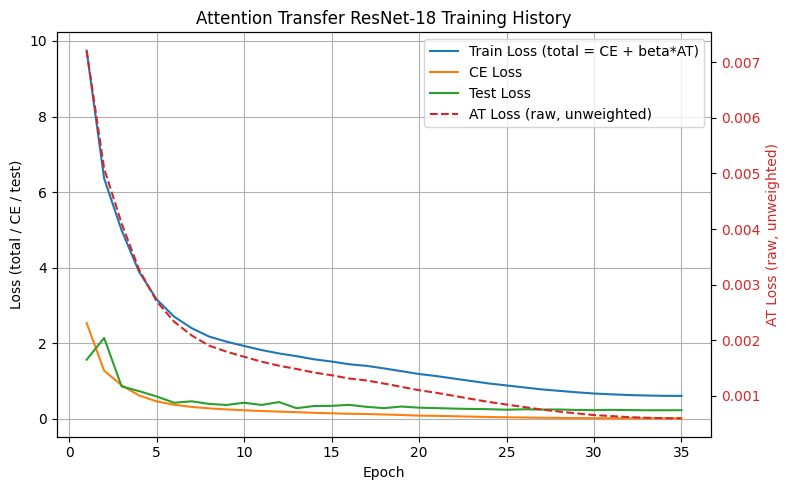

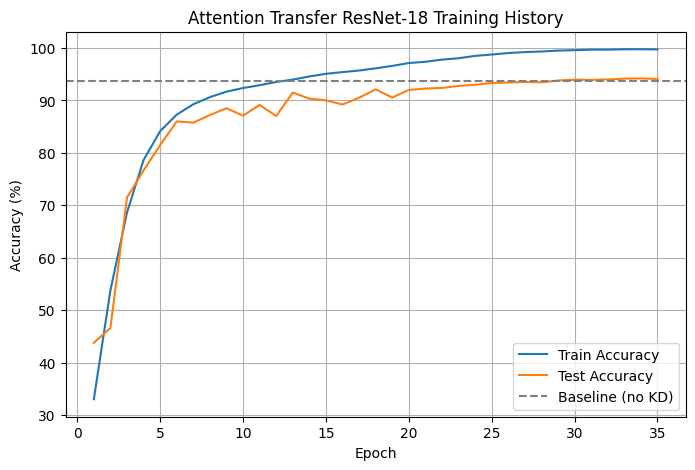

In [24]:
plot_history(at_history, "Attention Transfer ResNet-18 Training History")